
# C01b — Detector-Independent Surface Humanization (v2)

C01 identified a compact four-coordinate surface basis,

\[
M_{\rm surface}
=
(R_4,\mathrm{MATTR}_{50},CV_{\rm sent},F_{\rm function}),
\]

that retained essentially all of the detection signal carried by the seven formally
significant surface candidates.

C01b tests whether a **post-generation, non-detector-targeted rewrite** can move those
four coordinates toward matched human writing while preserving content and leaving
structural \(U/L\) comparatively stable.

## Important v2 changes

This version fixes the GPU-memory problem from the first draft:

1. the Qwen2.5 rewriter is loaded **before** any semantic encoder;
2. all rewrite candidates are generated and checkpointed;
3. the rewriter is deleted and CUDA memory is cleared;
4. only then is the cached Qwen3-0.6B-Base semantic encoder loaded;
5. semantic preservation uses a **source-normalized cosine**, not raw Qwen hidden-state
   cosine.

Raw mean-pooled base-LM embeddings are strongly anisotropic. Therefore, for source \(x\),
candidate \(x'\), and a deterministic unrelated same-domain reference \(z\),

\[
S_{\rm sem}(x,x')
=
\frac{
\cos(e_x,e_{x'})-\cos(e_x,e_z)
}{
1-\cos(e_x,e_z)
}.
\]

Thus:

- identical text has \(S_{\rm sem}=1\);
- an unrelated same-domain reference has \(S_{\rm sem}\approx0\);
- a close paraphrase should remain near 1.

The frozen semantic gate is

\[
S_{\rm sem}\ge 0.75.
\]

## Humanization objective

For each domain and target metric, the target is the human central 80% interval
\([q_{.10},q_{.90}]\). A candidate gets zero penalty once it lands inside that interval.
The original L000 text is always a fallback.

A rewrite is adopted only if it:

- preserves paragraph count exactly;
- preserves the multiset of numerical strings exactly;
- stays within a word-count ratio of \([0.80,1.20]\);
- has source-normalized semantic similarity \(\ge0.75\);
- preserves at least 60% of salient content tokens;
- improves the frozen surface objective by at least 10%.

External detectors are tested only after this notebook passes its surface, preservation,
and structural-selectivity gates.


In [1]:

from pathlib import Path
from collections import Counter
import gc
import re
import time

import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm

from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForCausalLM,
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score


cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
RESULTS = ROOT / "results"

C00B_DIR = (
    RESULTS
    / "causal"
    / "C00b_soft_self_history_attenuation"
)

C01_DIR = (
    RESULTS
    / "causal"
    / "C01_surface_trace_gap_characterization"
)

OUT = (
    RESULTS
    / "causal"
    / "C01b_surface_humanization_intervention"
)

OUT.mkdir(
    parents=True,
    exist_ok=True,
)

C01_SURFACE_PATH = (
    C01_DIR
    / "surface_features_long.parquet"
)

C00B_GEN_PATH = (
    C00B_DIR
    / "generations.parquet"
)

C00B_ANALYSIS_PATH = (
    C00B_DIR
    / "analysis_long.parquet"
)

for p in [
    C01_SURFACE_PATH,
    C00B_GEN_PATH,
    C00B_ANALYSIS_PATH,
]:
    assert p.exists(), (
        f"Missing prerequisite: {p}"
    )


surface_c01 = pd.read_parquet(
    C01_SURFACE_PATH
).copy()

generations = pd.read_parquet(
    C00B_GEN_PATH
).copy()

c00b_analysis = pd.read_parquet(
    C00B_ANALYSIS_PATH
).copy()


for df in [
    surface_c01,
    generations,
    c00b_analysis,
]:
    df["source_id"] = (
        df["source_id"]
        .astype(str)
    )


SOURCE_IDS = sorted(
    generations.loc[
        generations[
            "condition"
        ].eq("L000"),
        "source_id",
    ].unique()
)

assert len(SOURCE_IDS) == 60


TARGET_METRICS = [
    "repeat4_fraction",
    "mattr50",
    "sentence_cv",
    "function_word_rate",
]

VALIDATION_METRICS = [
    "distinct4",
    "adjacent_sentence_change",
]


REWRITER_CHECKPOINT = (
    "Qwen/Qwen2.5-1.5B-Instruct"
)

EMBED_CHECKPOINT = (
    "Qwen/Qwen3-0.6B-Base"
)

SCORER_CHECKPOINT = (
    "Qwen/Qwen3-0.6B-Base"
)


QUALITY = {
    "word_ratio_low": 0.80,
    "word_ratio_high": 1.20,
    "normalized_semantic_similarity": 0.75,
    "content_token_recall": 0.60,
}

MIN_RELATIVE_IMPROVEMENT = 0.10

N_BOOT = 10_000
SEED = 20260902


DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

DTYPE = (
    torch.float16
    if DEVICE.type == "cuda"
    else torch.float32
)


print("ROOT:", ROOT)
print("OUT:", OUT)
print("sources:", len(SOURCE_IDS))
print("targets:", TARGET_METRICS)
print("device:", DEVICE)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
OUT: ../results/causal/C01b_surface_humanization_intervention
sources: 60
targets: ['repeat4_fraction', 'mattr50', 'sentence_cv', 'function_word_rate']
device: cuda


## 1. Recover L000 and matched human texts

In [2]:

HUMAN_CACHE_CANDIDATES = [
    C01_DIR
    / "matched_human_texts.parquet",

    RESULTS
    / "causal"
    / "C00c_detector_transfer_under_history_humanization"
    / "matched_human_texts.parquet",
]

HUMAN_CACHE = next(
    (
        p
        for p in HUMAN_CACHE_CANDIDATES
        if p.exists()
    ),
    None,
)

assert HUMAN_CACHE is not None, (
    "Could not find the matched human text cache."
)


human_text = pd.read_parquet(
    HUMAN_CACHE
).copy()

human_text["source_id"] = (
    human_text["source_id"]
    .astype(str)
)


l000 = (
    generations[
        generations[
            "condition"
        ].eq("L000")
    ][
        [
            "source_id",
            "generated_text",
        ]
    ]
    .rename(
        columns={
            "generated_text":
                "original_text"
        }
    )
    .copy()
)


domain_map = (
    surface_c01[
        [
            "source_id",
            "domain",
        ]
    ]
    .drop_duplicates(
        "source_id"
    )
    .set_index(
        "source_id"
    )[
        "domain"
    ]
)


l000["domain"] = (
    l000["source_id"]
    .map(domain_map)
)


assert len(l000) == 60

assert (
    human_text["source_id"]
    .nunique()
    == 60
)

assert not (
    l000["domain"]
    .isna()
    .any()
)


display(
    l000.groupby(
        "domain"
    )
    .size()
    .rename("n")
    .to_frame()
)


,n
domain,
news,30
wiki,30


## 2. Freeze domain-conditioned human target ranges

In [3]:

human_surface = (
    surface_c01[
        surface_c01[
            "condition"
        ].eq("human")
    ]
    .copy()
)


target_rows = []


for domain in sorted(
    human_surface[
        "domain"
    ].unique()
):
    d = human_surface[
        human_surface[
            "domain"
        ].eq(domain)
    ]

    for metric in TARGET_METRICS:
        x = (
            d[metric]
            .dropna()
            .to_numpy(float)
        )

        (
            q10,
            q25,
            q50,
            q75,
            q90,
        ) = np.quantile(
            x,
            [
                0.10,
                0.25,
                0.50,
                0.75,
                0.90,
            ],
        )

        robust_scale = max(
            (q75 - q25) / 1.349,
            np.std(
                x,
                ddof=1,
            ),
            1e-6,
        )

        target_rows.append({
            "domain":
                domain,

            "metric":
                metric,

            "q10":
                q10,

            "q25":
                q25,

            "median":
                q50,

            "q75":
                q75,

            "q90":
                q90,

            "robust_scale":
                robust_scale,
        })


human_targets = pd.DataFrame(
    target_rows
)


human_targets.to_csv(
    OUT
    / "frozen_human_surface_targets.csv",
    index=False,
)


display(
    human_targets
)


,domain,metric,q10,q25,median,q75,q90,robust_scale
0,news,repeat4_fraction,0.000000,0.005074,0.008821,0.014555,0.022891,0.039320
1,news,mattr50,0.798736,0.817338,0.830958,0.838698,0.857138,0.022250
2,news,sentence_cv,0.333452,0.362914,0.390683,0.417836,0.437509,0.043351
3,news,function_word_rate,0.385716,0.390617,0.408528,0.437835,0.447813,0.038420
4,wiki,repeat4_fraction,0.000000,0.000000,0.011166,0.029672,0.044086,0.023544
5,wiki,mattr50,0.686719,0.745067,0.768057,0.790843,0.810607,0.052473
6,wiki,sentence_cv,0.347726,0.370626,0.433099,0.602745,0.754474,0.262708
7,wiki,function_word_rate,0.326932,0.365867,0.389879,0.412367,0.428072,0.063034


## 3. Reproduce the C01 surface metrics exactly

In [4]:

WORD_RE = re.compile(
    r"[A-Za-z]+(?:'[A-Za-z]+)?"
)

SENT_SPLIT_RE = re.compile(
    r"(?<=[.!?])"
    r"(?:[\"')\]]+)?"
    r"\s+"
)


FUNCTION_WORDS = {
    "a","an","the","and","or","but","if","while","although","though","because","since",
    "as","of","to","in","on","at","by","for","from","with","without","about","into",
    "through","during","before","after","above","below","between","among","against",
    "is","am","are","was","were","be","been","being","do","does","did","have","has","had",
    "can","could","may","might","must","shall","should","will","would",
    "i","me","my","mine","we","us","our","ours","you","your","yours",
    "he","him","his","she","her","hers","it","its","they","them","their","theirs",
    "this","that","these","those","who","whom","whose","which","what",
    "where","when","why","how","not","no","nor","so","than","then","there","here",
}


CONTRACTION_RE = re.compile(
    r"\b(?:"
    r"[A-Za-z]+n't"
    r"|"
    r"[A-Za-z]+'(?:re|ve|ll|d|m|s)"
    r")\b",
    flags=re.IGNORECASE,
)


def words(text):
    return [
        w.lower()
        for w
        in WORD_RE.findall(
            str(text)
        )
    ]


def sentences(text):
    text = re.sub(
        r"\s+",
        " ",
        str(text),
    ).strip()

    if not text:
        return []

    s = [
        x.strip()
        for x
        in SENT_SPLIT_RE.split(
            text
        )
        if x.strip()
    ]

    return (
        s
        if s
        else [text]
    )


def paragraphs(text):
    ps = [
        re.sub(
            r"\s+",
            " ",
            p,
        ).strip()

        for p
        in re.split(
            r"\n\s*\n",
            str(text),
        )

        if p.strip()
    ]

    return (
        ps
        if ps
        else [
            re.sub(
                r"\s+",
                " ",
                str(text),
            ).strip()
        ]
    )


def mattr(
    tokens,
    window=50,
):
    n = len(tokens)

    if n == 0:
        return np.nan

    if n <= window:
        return (
            len(set(tokens))
            / n
        )

    return float(
        np.mean([
            len(
                set(
                    tokens[
                        i:i+window
                    ]
                )
            )
            / window

            for i
            in range(
                n - window + 1
            )
        ])
    )


def lexical_entropy_norm(
    tokens,
):
    if len(tokens) <= 1:
        return np.nan

    counts = np.array(
        list(
            Counter(
                tokens
            ).values()
        ),
        dtype=float,
    )

    p = (
        counts
        / counts.sum()
    )

    H = -np.sum(
        p * np.log(p)
    )

    V = len(counts)

    return (
        0.0
        if V <= 1
        else float(
            H / np.log(V)
        )
    )


def rate100(
    count,
    n_words,
):
    return (
        100.0
        * count
        / n_words

        if n_words
        else np.nan
    )


def surface_features(
    text,
):
    text = str(text)

    toks = words(
        text
    )

    n_words = len(
        toks
    )

    sent_lens = np.array(
        [
            len(
                words(s)
            )
            for s
            in sentences(text)
        ],
        dtype=float,
    )

    sent_lens = sent_lens[
        sent_lens > 0
    ]

    counts = Counter(
        toks
    )


    if n_words:
        hapax = sum(
            c
            for c
            in counts.values()
            if c == 1
        )

        function_rate = np.mean([
            w in FUNCTION_WORDS
            for w
            in toks
        ])

        long_word_rate = np.mean([
            len(w) >= 8
            for w
            in toks
        ])

        mean_word_len = np.mean([
            len(w)
            for w
            in toks
        ])

    else:
        hapax = np.nan
        function_rate = np.nan
        long_word_rate = np.nan
        mean_word_len = np.nan


    if len(sent_lens):
        mean_sentence_words = float(
            sent_lens.mean()
        )

        sentence_cv = (
            float(
                sent_lens.std(
                    ddof=1
                )
                / sent_lens.mean()
            )

            if (
                len(sent_lens) >= 2
                and sent_lens.mean() > 0
            )
            else 0.0
        )

        adjacent_sentence_change = (
            float(
                np.mean(
                    np.abs(
                        np.diff(
                            sent_lens
                        )
                    )
                )
                / sent_lens.mean()
            )

            if (
                len(sent_lens) >= 2
                and sent_lens.mean() > 0
            )
            else 0.0
        )

    else:
        mean_sentence_words = np.nan
        sentence_cv = np.nan
        adjacent_sentence_change = np.nan


    result = {
        "word_count":
            n_words,

        "sentence_count":
            len(sent_lens),

        "mean_word_len":
            mean_word_len,

        "long_word_rate":
            long_word_rate,

        "mattr50":
            mattr(
                toks,
                50,
            ),

        "hapax_token_rate":
            (
                hapax
                / n_words

                if n_words
                else np.nan
            ),

        "lexical_entropy_norm":
            lexical_entropy_norm(
                toks
            ),

        "function_word_rate":
            function_rate,

        "contraction_rate_per100":
            rate100(
                len(
                    CONTRACTION_RE.findall(
                        text
                    )
                ),
                n_words,
            ),

        "mean_sentence_words":
            mean_sentence_words,

        "sentence_cv":
            sentence_cv,

        "adjacent_sentence_change":
            adjacent_sentence_change,

        "comma_rate_per100":
            rate100(
                text.count(","),
                n_words,
            ),

        "semicolon_colon_rate_per100":
            rate100(
                text.count(";")
                + text.count(":"),
                n_words,
            ),

        "dash_rate_per100":
            rate100(
                text.count("—")
                + text.count("–"),
                n_words,
            ),

        "paren_rate_per100":
            rate100(
                text.count("(")
                + text.count(")"),
                n_words,
            ),
    }


    if len(toks) >= 4:
        grams = [
            tuple(
                toks[
                    i:i+4
                ]
            )

            for i
            in range(
                len(toks) - 3
            )
        ]

        gcnt = Counter(
            grams
        )

        N = len(
            grams
        )

        result.update({
            "repeat4_fraction":
                sum(
                    c
                    for c
                    in gcnt.values()
                    if c > 1
                )
                / N,

            "distinct4":
                len(gcnt)
                / N,

            "max_repeat4_rate":
                max(
                    gcnt.values()
                )
                / N,
        })

    else:
        result.update({
            "repeat4_fraction":
                np.nan,

            "distinct4":
                np.nan,

            "max_repeat4_rate":
                np.nan,
        })


    return result


FEATURE_COLS = [
    "mean_word_len",
    "long_word_rate",
    "mattr50",
    "hapax_token_rate",
    "lexical_entropy_norm",
    "function_word_rate",
    "contraction_rate_per100",
    "mean_sentence_words",
    "sentence_cv",
    "adjacent_sentence_change",
    "comma_rate_per100",
    "semicolon_colon_rate_per100",
    "dash_rate_per100",
    "paren_rate_per100",
    "repeat4_fraction",
    "distinct4",
    "max_repeat4_rate",
]


## 4. Frozen surface-humanization objective

In [5]:

target_lookup = {
    (
        r["domain"],
        r["metric"],
    ): r

    for _, r
    in human_targets.iterrows()
}


def interval_distance(
    value,
    target_row,
):
    if not np.isfinite(
        value
    ):
        return np.inf

    lo = float(
        target_row[
            "q10"
        ]
    )

    hi = float(
        target_row[
            "q90"
        ]
    )

    scale = float(
        target_row[
            "robust_scale"
        ]
    )

    if (
        lo
        <= value
        <= hi
    ):
        return 0.0

    boundary = (
        lo
        if value < lo
        else hi
    )

    return (
        abs(
            value
            - boundary
        )
        / scale
    )


def surface_objective(
    text,
    domain,
):
    feats = surface_features(
        text
    )

    components = {
        metric:
            interval_distance(
                feats[
                    metric
                ],
                target_lookup[
                    (
                        domain,
                        metric,
                    )
                ],
            )

        for metric
        in TARGET_METRICS
    }

    objective = float(
        sum(
            v * v
            for v
            in components.values()
        )
    )

    return (
        objective,
        components,
        feats,
    )


baseline_rows = []

for _, r in l000.iterrows():
    (
        obj,
        comp,
        _,
    ) = surface_objective(
        r[
            "original_text"
        ],
        r[
            "domain"
        ],
    )

    baseline_rows.append({
        "source_id":
            r[
                "source_id"
            ],

        "domain":
            r[
                "domain"
            ],

        "baseline_objective":
            obj,

        **{
            f"distance_{k}":
                v

            for k, v
            in comp.items()
        },
    })


baseline_objectives = pd.DataFrame(
    baseline_rows
)


display(
    baseline_objectives[
        "baseline_objective"
    ]
    .describe()
    .to_frame()
    .T
)


,count,mean,std,min,25%,50%,75%,max
baseline_objective,60.0,104.317582,298.377235,0.053666,4.828147,16.081368,48.977326,1639.748764



## 5. Frozen rewrite strategies

Every candidate is generated **directly from the original L000 text**, never from another
candidate. No detector or structural metric appears in these prompts.


In [6]:

STRATEGIES = {
    "lexical_recurrence": (
        "Revise the text with a light editorial pass focused on local wording.\n\n"
        "Preserve every fact, claim, named entity, number, date, quotation, and paragraph "
        "in the same order. Do not add or remove information.\n\n"
        "Reduce unnecessary reuse of the same multi-word wording when the same point can "
        "be expressed naturally another way. Use a somewhat broader but ordinary vocabulary. "
        "Keep the argument and paragraph structure unchanged."
    ),

    "sentence_rhythm": (
        "Revise the text with a light editorial pass focused on sentence construction.\n\n"
        "Preserve every fact, claim, named entity, number, date, quotation, and paragraph "
        "in the same order. Do not add or remove information.\n\n"
        "Make sentence lengths and constructions less mechanically uniform. Where natural, "
        "split an overloaded sentence, combine two short closely related sentences, or vary "
        "clause structure. Do not reorder ideas or paragraphs."
    ),

    "compact_syntax": (
        "Revise the text with a light editorial pass focused on syntactic economy.\n\n"
        "Preserve every fact, claim, named entity, number, date, quotation, and paragraph "
        "in the same order. Do not add or remove information.\n\n"
        "Prefer concise active constructions where natural. Remove unnecessary filler, "
        "determiners, auxiliary phrasing, or prepositional scaffolding only when meaning "
        "and logical relations remain identical."
    ),

    "balanced_surface": (
        "Revise the text with a restrained general copy-edit.\n\n"
        "Preserve every fact, claim, named entity, number, date, quotation, and paragraph "
        "in the same order. Do not add or remove information.\n\n"
        "Use natural lexical variation when wording repeats unnecessarily, vary sentence "
        "length and clause structure so the prose is not mechanically uniform, and prefer "
        "concise syntax where this does not change meaning. Keep the same discourse plan "
        "and paragraph order."
    ),
}


print(
    "strategies:",
    list(
        STRATEGIES
    ),
)


strategies: ['lexical_recurrence', 'sentence_rhythm', 'compact_syntax', 'balanced_surface']



## 6. Generate four deterministic rewrite candidates per source

This is the expensive generation step. The semantic encoder is **not loaded yet**, so the
1.5B rewriter has the GPU to itself.

The cell checkpoints after each source and can resume safely.


In [13]:
# ============================================================
# C01b — resume-safe rewrite generation
#
# - Loads ONLY the Qwen2.5 rewriter
# - Rewrites paragraph-by-paragraph
# - Resumes from rewrite_candidates.parquet
# - Skips all already-completed candidates
# - Saves after EVERY individual strategy
# - Clears transient CUDA allocations aggressively
# ============================================================

CANDIDATE_PATH = (
    OUT
    / "rewrite_candidates.parquet"
)


# ------------------------------------------------------------
# 0. Start from a clean CUDA state
# ------------------------------------------------------------

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

    print(
        "GPU allocated before rewriter load:",
        round(
            torch.cuda.memory_allocated()
            / 1e9,
            3,
        ),
        "GB",
    )


# ------------------------------------------------------------
# 1. Load rewriter only
# ------------------------------------------------------------

rewriter_tok = AutoTokenizer.from_pretrained(
    REWRITER_CHECKPOINT,
    local_files_only=True,
)

rewriter = AutoModelForCausalLM.from_pretrained(
    REWRITER_CHECKPOINT,
    dtype=DTYPE,
    local_files_only=True,
)

rewriter.eval().to(
    DEVICE
)


if torch.cuda.is_available():

    print(
        "GPU allocated after rewriter load:",
        round(
            torch.cuda.memory_allocated()
            / 1e9,
            3,
        ),
        "GB",
    )


# ------------------------------------------------------------
# 2. Paragraph-level rewrite
#
# This deliberately prevents the rewriter from reconsidering
# the document's global discourse plan.
# ------------------------------------------------------------

@torch.inference_mode()
def rewrite_paragraph(
    paragraph,
    instruction,
):

    messages = [
        {
            "role": "system",
            "content": (
                "You are a conservative copy editor. "
                "Preserve all information exactly. "
                "Return only the revised paragraph."
            ),
        },
        {
            "role": "user",
            "content": (
                instruction.strip()
                + "\n\n"
                + "Rewrite ONLY the paragraph below. "
                  "Preserve every fact, name, number, date, "
                  "quotation, claim, and logical relation. "
                  "Do not add or remove information.\n\n"
                + "PARAGRAPH:\n"
                + str(paragraph)
            ),
        },
    ]


    enc = rewriter_tok.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True,
    )


    enc = {
        k: v.to(DEVICE)
        for k, v
        in enc.items()
    }


    input_len = (
        enc["input_ids"]
        .shape[1]
    )


    source_tokens = len(
        rewriter_tok(
            str(paragraph),
            add_special_tokens=False,
        )["input_ids"]
    )


    # Keep rewrite length relatively close to source.
    # Paragraph-level generation should not need huge budgets.
    max_new = int(
        min(
            350,
            max(
                80,
                source_tokens * 1.20 + 40,
            ),
        )
    )


    try:

        y = rewriter.generate(
            **enc,

            max_new_tokens=max_new,

            do_sample=False,

            # Paragraphs are short enough that cache is useful,
            # while remaining far smaller than document-level KV.
            use_cache=True,

            pad_token_id=
                rewriter_tok.eos_token_id,

            eos_token_id=
                rewriter_tok.eos_token_id,
        )


        text = rewriter_tok.decode(
            y[
                0,
                input_len:,
            ],
            skip_special_tokens=True,
        ).strip()


    finally:

        # Ensure prompt tensors are released even if generation
        # raises an exception.
        del enc

        if "y" in locals():
            del y

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


    if text.startswith("```"):

        text = re.sub(
            r"^```(?:text)?\s*",
            "",
            text,
        )

        text = re.sub(
            r"\s*```$",
            "",
            text,
        )


    return text.strip()


# ------------------------------------------------------------
# 3. Full-document surface rewrite
#
# Paragraph count and order are preserved by construction.
# ------------------------------------------------------------

@torch.inference_mode()
def rewrite_once(
    original_text,
    instruction,
):

    source_paragraphs = paragraphs(
        original_text
    )

    rewritten_paragraphs = []


    for paragraph in source_paragraphs:

        revised = rewrite_paragraph(
            paragraph,
            instruction,
        )

        # Never silently drop a paragraph.
        if not revised.strip():
            revised = paragraph

        rewritten_paragraphs.append(
            revised
        )


    assert (
        len(rewritten_paragraphs)
        == len(source_paragraphs)
    )


    return "\n\n".join(
        rewritten_paragraphs
    )


# ------------------------------------------------------------
# 4. Load the existing checkpoint
#
# You currently have 232/240 rows here.
# ------------------------------------------------------------

assert CANDIDATE_PATH.exists(), (
    "Expected the existing 232-row checkpoint at:\n"
    f"{CANDIDATE_PATH}"
)


candidates = pd.read_parquet(
    CANDIDATE_PATH
)

candidates["source_id"] = (
    candidates["source_id"]
    .astype(str)
)


assert not candidates.duplicated(
    [
        "source_id",
        "strategy",
    ]
).any()


done = set(
    zip(
        candidates[
            "source_id"
        ].astype(str),

        candidates[
            "strategy"
        ].astype(str),
    )
)


expected = {
    (
        str(sid),
        strategy,
    )

    for sid
    in SOURCE_IDS

    for strategy
    in STRATEGIES
}


missing = expected - done


print(
    "\nalready safely saved:",
    len(done),
    "/",
    len(expected),
)

print(
    "remaining candidates:",
    len(missing),
)


for item in sorted(missing):
    print(
        "  ",
        item,
    )


# ------------------------------------------------------------
# 5. Generate ONLY missing candidates
#
# Save after EVERY strategy.
# ------------------------------------------------------------

for _, r in tqdm(
    l000.iterrows(),
    total=len(l000),
    desc="sources",
):

    sid = str(
        r["source_id"]
    )


    missing_for_source = [
        strategy

        for strategy
        in STRATEGIES

        if (
            sid,
            strategy,
        ) not in done
    ]


    # 58/60 sources should immediately hit this branch.
    if not missing_for_source:
        continue


    print(
        "\n"
        + "=" * 90
    )

    print(
        "SOURCE:",
        sid,
    )

    print(
        "remaining strategies:",
        missing_for_source,
    )


    for strategy in missing_for_source:

        key = (
            sid,
            strategy,
        )


        # Clean transient allocator state before each candidate.
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


        print(
            f"\nGenerating: {sid} | {strategy}"
        )


        if torch.cuda.is_available():

            print(
                "before generation — allocated:",
                round(
                    torch.cuda.memory_allocated()
                    / 1e9,
                    3,
                ),
                "GB | reserved:",
                round(
                    torch.cuda.memory_reserved()
                    / 1e9,
                    3,
                ),
                "GB",
            )


        t0 = time.time()


        text = rewrite_once(
            r["original_text"],
            STRATEGIES[
                strategy
            ],
        )


        seconds = (
            time.time()
            - t0
        )


        new_row = pd.DataFrame([
            {
                "source_id":
                    sid,

                "domain":
                    r["domain"],

                "strategy":
                    strategy,

                "candidate_text":
                    text,

                "seconds":
                    seconds,
            }
        ])


        candidates = pd.concat(
            [
                candidates,
                new_row,
            ],
            ignore_index=True,
        )


        # ----------------------------------------------------
        # CRITICAL:
        # checkpoint this individual candidate immediately.
        # ----------------------------------------------------

        candidates.to_parquet(
            CANDIDATE_PATH,
            index=False,
        )


        done.add(
            key
        )


        print(
            "SAVED:",
            len(done),
            "/",
            len(expected),
        )


        print(
            "time:",
            round(
                seconds,
                1,
            ),
            "sec",
        )


        del text
        del new_row


        gc.collect()

        if torch.cuda.is_available():

            torch.cuda.empty_cache()

            print(
                "after save — allocated:",
                round(
                    torch.cuda.memory_allocated()
                    / 1e9,
                    3,
                ),
                "GB | reserved:",
                round(
                    torch.cuda.memory_reserved()
                    / 1e9,
                    3,
                ),
                "GB",
            )


# ------------------------------------------------------------
# 6. Final integrity checks
# ------------------------------------------------------------

candidates = pd.read_parquet(
    CANDIDATE_PATH
)

candidates["source_id"] = (
    candidates["source_id"]
    .astype(str)
)


print(
    "\n"
    + "=" * 90
)

print(
    "FINAL SAVED ROWS:",
    len(candidates),
)


assert len(candidates) == (
    len(SOURCE_IDS)
    * len(STRATEGIES)
), (
    f"Expected 240 candidates, got {len(candidates)}"
)


assert not candidates.duplicated(
    [
        "source_id",
        "strategy",
    ]
).any()


final_pairs = set(
    zip(
        candidates[
            "source_id"
        ].astype(str),

        candidates[
            "strategy"
        ].astype(str),
    )
)


assert final_pairs == expected


print(
    "PASS: all 240 rewrite candidates are safely on disk."
)

print(
    "saved:",
    CANDIDATE_PATH,
)

GPU allocated before rewriter load: 3.097 GB


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 1025.12it/s]


GPU allocated after rewriter load: 3.097 GB

already safely saved: 240 / 240
remaining candidates: 0


sources: 100%|███████████████████████████████████████████████████████████████████████████████████████| 60/60 [00:00<00:00, 15184.83it/s]


FINAL SAVED ROWS: 240
PASS: all 240 rewrite candidates are safely on disk.
saved: ../results/causal/C01b_surface_humanization_intervention/rewrite_candidates.parquet



## 7. Free the rewriter, then load the cached semantic-preservation encoder

The base-LM embedding space is anisotropic, so raw cosine is retained only for audit.
Candidate eligibility uses source-normalized cosine against a deterministic unrelated
**same-domain** L000 document.


In [14]:

# Free the 1.5B rewriter before loading Qwen3.
del rewriter
del rewriter_tok

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

    print(
        "GPU allocated after freeing rewriter:",
        torch.cuda.memory_allocated()
        / 1e9,
        "GB",
    )


embed_tok = AutoTokenizer.from_pretrained(
    EMBED_CHECKPOINT,
    local_files_only=True,
)


embed_model = AutoModel.from_pretrained(
    EMBED_CHECKPOINT,
    dtype=DTYPE,
    local_files_only=True,
)


embed_model.eval().to(
    DEVICE
)


@torch.inference_mode()
def embed_texts(
    texts,
    batch_size=8,
):
    outputs = []


    for start in range(
        0,
        len(texts),
        batch_size,
    ):
        batch = texts[
            start:
            start + batch_size
        ]


        enc = embed_tok(
            batch,
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt",
        ).to(
            DEVICE
        )


        out = embed_model(
            **enc
        )


        token_emb = (
            out.last_hidden_state
        )


        mask = (
            enc[
                "attention_mask"
            ]
            .unsqueeze(-1)
        )


        emb = (
            (
                token_emb
                * mask
            ).sum(
                dim=1
            )
            /
            mask.sum(
                dim=1
            ).clamp_min(
                1
            )
        )


        emb = torch.nn.functional.normalize(
            emb.float(),
            p=2,
            dim=1,
        )


        outputs.append(
            emb.cpu()
        )


    return (
        torch.cat(
            outputs,
            dim=0,
        )
        .numpy()
    )


# Precompute the original L000 embeddings once.
_original_texts = (
    l000.set_index(
        "source_id"
    )[
        "original_text"
    ]
    .to_dict()
)


_original_domains = (
    l000.set_index(
        "source_id"
    )[
        "domain"
    ]
    .to_dict()
)


_original_matrix = embed_texts(
    [
        _original_texts[
            sid
        ]
        for sid
        in SOURCE_IDS
    ]
)


_original_emb = {
    sid:
        _original_matrix[
            i
        ]

    for i, sid
    in enumerate(
        SOURCE_IDS
    )
}


# Deterministic unrelated same-domain reference.
_negative_id = {}


for domain in sorted(
    set(
        _original_domains.values()
    )
):
    ids = sorted([
        sid
        for sid
        in SOURCE_IDS
        if _original_domains[
            sid
        ] == domain
    ])


    # 13 is coprime with 30 and far from the immediate neighbor.
    for i, sid in enumerate(
        ids
    ):
        _negative_id[
            sid
        ] = ids[
            (
                i + 13
            )
            % len(ids)
        ]


_negative_baseline_cos = {
    sid:
        float(
            _original_emb[
                sid
            ]
            @
            _original_emb[
                _negative_id[
                    sid
                ]
            ]
        )

    for sid
    in SOURCE_IDS
}


def normalized_semantic_from_embedding(
    source_id,
    candidate_embedding,
):
    sid = str(
        source_id
    )


    original_embedding = (
        _original_emb[
            sid
        ]
    )


    raw_candidate_cos = float(
        original_embedding
        @ candidate_embedding
    )


    raw_negative_cos = float(
        _negative_baseline_cos[
            sid
        ]
    )


    denom = (
        1.0
        - raw_negative_cos
    )


    normalized = (
        (
            raw_candidate_cos
            - raw_negative_cos
        )
        / denom

        if denom > 1e-6
        else np.nan
    )


    return {
        "raw_semantic_cosine":
            raw_candidate_cos,

        "negative_reference_cosine":
            raw_negative_cos,

        "normalized_semantic_similarity":
            float(
                normalized
            ),
    }


# Sanity check using the same toy pair as before.
_test = embed_texts([
    "The committee approved the proposal after reviewing it.",
    "After reviewing the proposal, the committee approved it.",
    "A volcano erupted on another planet.",
])


_test_para = float(
    _test[0]
    @ _test[1]
)


_test_negative = float(
    _test[0]
    @ _test[2]
)


_test_norm = (
    (
        _test_para
        - _test_negative
    )
    /
    (
        1.0
        - _test_negative
    )
)


print(
    "toy raw paraphrase cosine:",
    _test_para,
)

print(
    "toy raw unrelated cosine:",
    _test_negative,
)

print(
    "toy normalized paraphrase score:",
    _test_norm,
)

print(
    "source negative-reference cosine range:",
    min(
        _negative_baseline_cos.values()
    ),
    "to",
    max(
        _negative_baseline_cos.values()
    ),
)


GPU allocated after freeing rewriter: 0.00851968 GB


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 3261.35it/s]


toy raw paraphrase cosine: 0.984769344329834
toy raw unrelated cosine: 0.8514611124992371
toy normalized paraphrase score: 0.8974635132494325
source negative-reference cosine range: 0.7021182775497437 to 0.954548716545105


## 8. Hard quality checks

In [15]:

NUMBER_RE = re.compile(
    r"(?<!\w)"
    r"[+-]?"
    r"(?:"
        r"\d{1,3}"
        r"(?:,\d{3})*"
        r"|"
        r"\d+"
    r")"
    r"(?:\.\d+)?"
    r"%?"
    r"(?!\w)"
)


def number_multiset(
    text,
):
    return Counter(
        NUMBER_RE.findall(
            str(text)
        )
    )


def content_tokens(
    text,
):
    return {
        w

        for w
        in words(
            text
        )

        if (
            len(w) >= 6
            and w
            not in FUNCTION_WORDS
        )
    }


def content_token_recall(
    original,
    candidate,
):
    a = content_tokens(
        original
    )

    b = content_tokens(
        candidate
    )

    return (
        len(
            a & b
        )
        / len(a)

        if a
        else 1.0
    )


def candidate_quality(
    source_id,
    original,
    candidate,
    candidate_embedding,
):
    op = paragraphs(
        original
    )

    cp = paragraphs(
        candidate
    )


    ow = len(
        words(
            original
        )
    )

    cw = len(
        words(
            candidate
        )
    )


    word_ratio = (
        cw / ow
        if ow > 0
        else np.nan
    )


    sem = (
        normalized_semantic_from_embedding(
            source_id,
            candidate_embedding,
        )
    )


    q = {
        "paragraph_count_original":
            len(op),

        "paragraph_count_candidate":
            len(cp),

        "paragraph_count_exact":
            len(op) == len(cp),

        "numbers_exact":
            (
                number_multiset(
                    original
                )
                ==
                number_multiset(
                    candidate
                )
            ),

        "word_ratio":
            word_ratio,

        "content_token_recall":
            content_token_recall(
                original,
                candidate,
            ),

        **sem,
    }


    q[
        "quality_pass"
    ] = bool(
        q[
            "paragraph_count_exact"
        ]

        and q[
            "numbers_exact"
        ]

        and np.isfinite(
            q[
                "word_ratio"
            ]
        )

        and (
            QUALITY[
                "word_ratio_low"
            ]
            <= q[
                "word_ratio"
            ]
            <= QUALITY[
                "word_ratio_high"
            ]
        )

        and (
            q[
                "normalized_semantic_similarity"
            ]
            >= QUALITY[
                "normalized_semantic_similarity"
            ]
        )

        and (
            q[
                "content_token_recall"
            ]
            >= QUALITY[
                "content_token_recall"
            ]
        )
    )


    return q



## 9. Batch-embed all candidates, apply the frozen quality gate, and select the best eligible rewrite

Candidate embeddings are computed in batches once, which is much faster than repeatedly
running the semantic encoder inside the selection loop.


In [16]:

EVAL_PATH = (
    OUT
    / "candidate_evaluation.parquet"
)

SELECTED_PATH = (
    OUT
    / "surface_humanized_generations.parquet"
)


lookup = (
    l000
    .set_index(
        "source_id"
    )[
        [
            "original_text",
            "domain",
        ]
    ]
    .to_dict(
        "index"
    )
)


if EVAL_PATH.exists():
    candidate_eval = pd.read_parquet(
        EVAL_PATH
    )

    candidate_eval[
        "source_id"
    ] = candidate_eval[
        "source_id"
    ].astype(str)

    print(
        "loaded cached candidate evaluation:",
        candidate_eval.shape,
    )

else:
    print(
        "embedding",
        len(candidates),
        "candidate rewrites...",
    )


    candidate_embeddings = embed_texts(
        candidates[
            "candidate_text"
        ]
        .astype(str)
        .tolist(),
        batch_size=8,
    )


    rows = []


    for row_i, r in tqdm(
        candidates.reset_index(
            drop=True
        ).iterrows(),
        total=len(candidates),
        desc="candidate quality + objective",
    ):
        sid = str(
            r[
                "source_id"
            ]
        )

        original = lookup[
            sid
        ][
            "original_text"
        ]

        domain = lookup[
            sid
        ][
            "domain"
        ]

        candidate = r[
            "candidate_text"
        ]


        q = candidate_quality(
            sid,
            original,
            candidate,
            candidate_embeddings[
                row_i
            ],
        )


        (
            obj,
            comp,
            feats,
        ) = surface_objective(
            candidate,
            domain,
        )


        (
            base_obj,
            _,
            _,
        ) = surface_objective(
            original,
            domain,
        )


        relative_improvement = (
            (
                base_obj
                - obj
            )
            / base_obj

            if base_obj > 1e-12
            else 0.0
        )


        rows.append({
            "source_id":
                sid,

            "domain":
                domain,

            "strategy":
                r[
                    "strategy"
                ],

            "candidate_text":
                candidate,

            "baseline_objective":
                base_obj,

            "candidate_objective":
                obj,

            "relative_objective_improvement":
                relative_improvement,

            **q,

            **{
                f"distance_{k}":
                    v

                for k, v
                in comp.items()
            },

            **{
                f"candidate_{k}":
                    v

                for k, v
                in feats.items()
            },
        })


    candidate_eval = pd.DataFrame(
        rows
    )


    candidate_eval.to_parquet(
        EVAL_PATH,
        index=False,
    )


    print(
        "saved:",
        EVAL_PATH,
    )


selection_rows = []


for sid in SOURCE_IDS:
    original = lookup[
        sid
    ][
        "original_text"
    ]

    domain = lookup[
        sid
    ][
        "domain"
    ]


    (
        base_obj,
        _,
        _,
    ) = surface_objective(
        original,
        domain,
    )


    d = candidate_eval[
        candidate_eval[
            "source_id"
        ].eq(
            sid
        )
    ].copy()


    eligible = d[
        d[
            "quality_pass"
        ]
        & d[
            "relative_objective_improvement"
        ].ge(
            MIN_RELATIVE_IMPROVEMENT
        )
    ].copy()


    if len(
        eligible
    ):
        best = eligible.sort_values(
            [
                "candidate_objective",
                "strategy",
            ]
        ).iloc[
            0
        ]


        selected_text = best[
            "candidate_text"
        ]

        selected_strategy = best[
            "strategy"
        ]

        selected_obj = float(
            best[
                "candidate_objective"
            ]
        )

        rewritten = True

    else:
        selected_text = original
        selected_strategy = "original_L000"
        selected_obj = base_obj
        rewritten = False


    selection_rows.append({
        "source_id":
            sid,

        "domain":
            domain,

        "selected_strategy":
            selected_strategy,

        "rewritten":
            rewritten,

        "baseline_objective":
            base_obj,

        "selected_objective":
            selected_obj,

        "relative_objective_improvement":
            (
                (
                    base_obj
                    - selected_obj
                )
                / base_obj

                if base_obj > 1e-12
                else 0.0
            ),

        "original_text":
            original,

        "selected_text":
            selected_text,
    })


selected = pd.DataFrame(
    selection_rows
)


selected.to_parquet(
    SELECTED_PATH,
    index=False,
)


print(
    "rewritten:",
    int(
        selected[
            "rewritten"
        ].sum()
    ),
    "/",
    len(selected),
)


display(
    selected.groupby(
        "selected_strategy"
    )
    .size()
    .rename("n")
    .sort_values(
        ascending=False
    )
    .to_frame()
)


display(
    selected[
        "relative_objective_improvement"
    ]
    .describe()
    .to_frame()
    .T
)


embedding 240 candidate rewrites...


candidate quality + objective: 100%|█████████████████████████████████████████████████████████████████| 240/240 [00:00<00:00, 406.46it/s]


saved: ../results/causal/C01b_surface_humanization_intervention/candidate_evaluation.parquet
rewritten: 16 / 60


,n
selected_strategy,
original_L000,44
lexical_recurrence,6
sentence_rhythm,5
compact_syntax,3
balanced_surface,2


,count,mean,std,min,25%,50%,75%,max
relative_objective_improvement,60.0,0.201187,0.36141,0.0,0.0,0.0,0.343933,1.0


## 10. Selected-output quality audit

In [17]:

# Batch-embed all selected outputs once.
selected_embeddings = embed_texts(
    selected[
        "selected_text"
    ]
    .astype(str)
    .tolist(),
    batch_size=8,
)


quality_rows = []


for row_i, r in tqdm(
    selected.reset_index(
        drop=True
    ).iterrows(),
    total=len(selected),
    desc="selected quality audit",
):
    q = candidate_quality(
        r[
            "source_id"
        ],
        r[
            "original_text"
        ],
        r[
            "selected_text"
        ],
        selected_embeddings[
            row_i
        ],
    )


    quality_rows.append({
        "source_id":
            r[
                "source_id"
            ],

        "rewritten":
            r[
                "rewritten"
            ],

        **q,
    })


selected_quality = pd.DataFrame(
    quality_rows
)


selected_quality.to_csv(
    OUT
    / "selected_quality_audit.csv",
    index=False,
)


print(
    "rewrite retention:",
    selected[
        "rewritten"
    ].mean(),
)


if selected[
    "rewritten"
].any():

    print(
        "quality pass among rewritten:",
        selected_quality.loc[
            selected_quality[
                "rewritten"
            ],
            "quality_pass",
        ].mean(),
    )


display(
    selected_quality[
        [
            "word_ratio",
            "content_token_recall",
            "raw_semantic_cosine",
            "negative_reference_cosine",
            "normalized_semantic_similarity",
        ]
    ]
    .describe()
    .T
)


selected quality audit: 100%|█████████████████████████████████████████████████████████████████████████| 60/60 [00:00<00:00, 1283.92it/s]

rewrite retention: 0.26666666666666666
quality pass among rewritten: 1.0


,count,mean,std,min,25%,50%,75%,max
word_ratio,60.0,0.988381,0.060537,0.813411,1.000000,1.000000,1.000000,1.125000
content_token_recall,60.0,0.936764,0.130178,0.621622,1.000000,1.000000,1.000000,1.000000
raw_semantic_cosine,60.0,0.995016,0.009408,0.965260,0.993524,1.000000,1.000000,1.000000
negative_reference_cosine,60.0,0.836837,0.055457,0.702118,0.809651,0.840146,0.866011,0.954549
normalized_semantic_similarity,60.0,0.969522,0.059604,0.782475,0.967492,1.000000,1.000000,1.000002


## 11. Surface gap closure, including untargeted validation coordinates

In [18]:

selected_surface = pd.DataFrame([
    {
        "source_id":
            r[
                "source_id"
            ],

        "domain":
            r[
                "domain"
            ],

        "condition":
            "surface_humanized",

        **surface_features(
            r[
                "selected_text"
            ]
        ),
    }

    for _, r
    in selected.iterrows()
])


surface3 = pd.concat(
    [
        surface_c01[
            surface_c01[
                "condition"
            ].isin(
                [
                    "human",
                    "L000",
                ]
            )
        ],

        selected_surface,
    ],
    ignore_index=True,
)


surface3.to_parquet(
    OUT
    / "surface_features_human_L000_humanized.parquet",
    index=False,
)


wide = surface3.pivot(
    index="source_id",
    columns="condition",
    values=FEATURE_COLS,
)


rows = []


for i, metric in enumerate(
    FEATURE_COLS
):
    z = pd.concat(
        [
            wide[
                (
                    metric,
                    "human",
                )
            ].rename(
                "human"
            ),

            wide[
                (
                    metric,
                    "L000",
                )
            ].rename(
                "L000"
            ),

            wide[
                (
                    metric,
                    "surface_humanized",
                )
            ].rename(
                "surface"
            ),
        ],
        axis=1,
    ).dropna()


    h = z[
        "human"
    ].to_numpy(
        float
    )

    b = z[
        "L000"
    ].to_numpy(
        float
    )

    s = z[
        "surface"
    ].to_numpy(
        float
    )


    baseline_gap = np.mean(
        b - h
    )

    surface_gap = np.mean(
        s - h
    )

    shift = np.mean(
        s - b
    )


    closure = (
        1.0
        - surface_gap
        / baseline_gap

        if abs(
            baseline_gap
        ) > 1e-12
        else np.nan
    )


    rr = np.random.default_rng(
        SEED
        + 7000
        + i
    )


    bs_shift = np.empty(
        N_BOOT
    )

    bs_closure = np.full(
        N_BOOT,
        np.nan,
    )


    for k in range(
        N_BOOT
    ):
        ix = rr.integers(
            0,
            len(z),
            len(z),
        )


        bg = np.mean(
            b[ix]
            - h[ix]
        )

        sg = np.mean(
            s[ix]
            - h[ix]
        )


        bs_shift[k] = np.mean(
            s[ix]
            - b[ix]
        )


        if abs(
            bg
        ) > 1e-12:
            bs_closure[k] = (
                1.0
                - sg
                / bg
            )


    valid = np.isfinite(
        bs_closure
    )


    rows.append({
        "metric":
            metric,

        "target_metric":
            metric
            in TARGET_METRICS,

        "validation_metric":
            metric
            in VALIDATION_METRICS,

        "human_mean":
            float(
                h.mean()
            ),

        "L000_mean":
            float(
                b.mean()
            ),

        "surface_mean":
            float(
                s.mean()
            ),

        "surface_minus_L000":
            float(
                shift
            ),

        "shift_ci_low":
            float(
                np.quantile(
                    bs_shift,
                    0.025,
                )
            ),

        "shift_ci_high":
            float(
                np.quantile(
                    bs_shift,
                    0.975,
                )
            ),

        "gap_closure":
            float(
                closure
            )
            if np.isfinite(
                closure
            )
            else np.nan,

        "closure_ci_low":
            (
                float(
                    np.quantile(
                        bs_closure[
                            valid
                        ],
                        0.025,
                    )
                )

                if valid.any()
                else np.nan
            ),

        "closure_ci_high":
            (
                float(
                    np.quantile(
                        bs_closure[
                            valid
                        ],
                        0.975,
                    )
                )

                if valid.any()
                else np.nan
            ),
    })


surface_closure = pd.DataFrame(
    rows
)


surface_closure.to_csv(
    OUT
    / "surface_gap_closure.csv",
    index=False,
)


print(
    "=== TARGET + VALIDATION COORDINATES ==="
)


display(
    surface_closure[
        surface_closure[
            "target_metric"
        ]
        | surface_closure[
            "validation_metric"
        ]
    ]
)


=== TARGET + VALIDATION COORDINATES ===


,metric,target_metric,validation_metric,human_mean,L000_mean,surface_mean,surface_minus_L000,shift_ci_low,shift_ci_high,gap_closure,closure_ci_low,closure_ci_high
2,mattr50,True,False,0.794287,0.742616,0.752011,0.009395,-0.002562,0.021431,0.181816,-0.078371,0.456132
5,function_word_rate,True,False,0.393702,0.430676,0.421117,-0.009559,-0.018082,-0.001505,0.258530,0.033960,0.828054
8,sentence_cv,True,False,0.451199,0.265438,0.274497,0.009059,0.001824,0.017216,0.048768,0.009704,0.102359
9,adjacent_sentence_change,False,True,0.503415,0.275572,0.293756,0.018183,0.007309,0.031030,0.079806,0.030171,0.150503
14,repeat4_fraction,True,False,0.018880,0.180975,0.167738,-0.013237,-0.022817,-0.005632,0.081664,0.032271,0.158204
15,distinct4,False,True,0.989545,0.883504,0.892207,0.008703,0.003448,0.015180,0.082068,0.029955,0.170159


## 12. Transparent residual surface detectability

In [19]:

def oof_surface_transfer(
    feature_cols,
):
    d = surface3.copy()


    source_order = np.array(
        sorted(
            d[
                "source_id"
            ].unique()
        )
    )


    splitter = GroupKFold(
        n_splits=5
    )


    dummy = np.zeros(
        (
            len(
                source_order
            ),
            1,
        )
    )


    out = []


    for (
        fold,
        (
            train_i,
            test_i,
        ),
    ) in enumerate(
        splitter.split(
            dummy,
            groups=source_order,
        )
    ):
        train_ids = set(
            source_order[
                train_i
            ]
        )

        test_ids = set(
            source_order[
                test_i
            ]
        )


        train = d[
            d[
                "source_id"
            ].isin(
                train_ids
            )
            & d[
                "condition"
            ].isin(
                [
                    "human",
                    "L000",
                ]
            )
        ].copy()


        test = d[
            d[
                "source_id"
            ].isin(
                test_ids
            )
        ].copy()


        med = train[
            feature_cols
        ].median(
            numeric_only=True
        )


        X_train = train[
            feature_cols
        ].fillna(
            med
        )


        y_train = (
            train[
                "condition"
            ]
            .eq(
                "L000"
            )
            .astype(int)
            .to_numpy()
        )


        pipe = Pipeline([
            (
                "scale",
                StandardScaler(),
            ),
            (
                "clf",
                LogisticRegression(
                    C=1.0,
                    max_iter=5000,
                    random_state=
                        SEED + fold,
                ),
            ),
        ])


        pipe.fit(
            X_train,
            y_train,
        )


        prob = pipe.predict_proba(
            test[
                feature_cols
            ].fillna(
                med
            )
        )[:, 1]


        z = test[
            [
                "source_id",
                "condition",
            ]
        ].copy()


        z[
            "fold"
        ] = fold


        z[
            "machine_probability"
        ] = prob


        out.append(
            z
        )


    pred = pd.concat(
        out,
        ignore_index=True,
    )


    human_scores = pred.loc[
        pred[
            "condition"
        ].eq(
            "human"
        ),
        "machine_probability",
    ]


    rows = []


    for condition in [
        "L000",
        "surface_humanized",
    ]:
        machine_scores = pred.loc[
            pred[
                "condition"
            ].eq(
                condition
            ),
            "machine_probability",
        ]


        y = np.concatenate([
            np.zeros(
                len(
                    human_scores
                )
            ),
            np.ones(
                len(
                    machine_scores
                )
            ),
        ])


        score = np.concatenate([
            human_scores.to_numpy(
                float
            ),
            machine_scores.to_numpy(
                float
            ),
        ])


        rows.append({
            "condition":
                condition,

            "AUROC_vs_human":
                roc_auc_score(
                    y,
                    score,
                ),

            "human_mean_machine_prob":
                human_scores.mean(),

            "machine_mean_machine_prob":
                machine_scores.mean(),
        })


    return (
        pred,
        pd.DataFrame(
            rows
        ),
    )


(
    basis4_pred,
    basis4_perf,
) = oof_surface_transfer(
    TARGET_METRICS
)


(
    all17_pred,
    all17_perf,
) = oof_surface_transfer(
    FEATURE_COLS
)


basis4_perf[
    "detector"
] = "surface_basis_4"


all17_perf[
    "detector"
] = "surface_all_17"


surface_detector_transfer = pd.concat(
    [
        basis4_perf,
        all17_perf,
    ],
    ignore_index=True,
)


display(
    surface_detector_transfer
)


surface_detector_transfer.to_csv(
    OUT
    / "transparent_surface_detector_transfer.csv",
    index=False,
)


,condition,AUROC_vs_human,human_mean_machine_prob,machine_mean_machine_prob,detector
0,L000,0.945278,0.203011,0.797756,surface_basis_4
1,surface_humanized,0.890833,0.203011,0.705449,surface_basis_4
2,L000,0.973889,0.140377,0.855405,surface_all_17
3,surface_humanized,0.966667,0.140377,0.816083,surface_all_17



## 13. Free the semantic encoder, then rescore structural \(U/L\)

The selected surface-humanized outputs are rescored with the same frozen C00/C00b rule:

- `Qwen/Qwen3-0.6B-Base`;
- exactly 384 scorer tokens;
- contexts \(8,32,128,256\);
- eight fixed targets from positions 256 through 383;
- \(U(k)=L_8-L_k\).

The semantic encoder is freed first so the scorer has the GPU to itself.


In [20]:

# Free semantic encoder.
del embed_model
del embed_tok

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

    print(
        "GPU allocated before scorer load:",
        torch.cuda.memory_allocated()
        / 1e9,
        "GB",
    )


CONTEXTS = [
    8,
    32,
    128,
    256,
]


TARGET_POSITIONS = np.unique(
    np.linspace(
        256,
        383,
        8,
        dtype=int,
    )
)


STRUCT_PATH = (
    OUT
    / "surface_humanized_U_L.parquet"
)


if STRUCT_PATH.exists():
    surface_scores = pd.read_parquet(
        STRUCT_PATH
    )

    surface_scores[
        "source_id"
    ] = surface_scores[
        "source_id"
    ].astype(str)

else:
    score_tok = AutoTokenizer.from_pretrained(
        SCORER_CHECKPOINT,
        local_files_only=True,
    )


    scorer = AutoModelForCausalLM.from_pretrained(
        SCORER_CHECKPOINT,
        dtype=DTYPE,
        local_files_only=True,
    )


    scorer.eval().to(
        DEVICE
    )


    @torch.inference_mode()
    def nll_at_context(
        ids,
        target,
        k,
    ):
        start = max(
            0,
            target - k,
        )


        x = torch.tensor(
            ids[
                start:
                target + 1
            ],
            dtype=torch.long,
            device=DEVICE,
        )[
            None,
            :,
        ]


        logits = scorer(
            input_ids=x
        ).logits


        pred = logits[
            0,
            -2,
        ].float()


        y = torch.tensor(
            [
                ids[
                    target
                ]
            ],
            dtype=torch.long,
            device=DEVICE,
        )


        return float(
            torch.nn.functional.cross_entropy(
                pred[
                    None,
                    :,
                ],
                y,
            ).item()
        )


    def score_structural(
        text,
    ):
        ids = score_tok(
            str(text),
            add_special_tokens=False,
            truncation=True,
            max_length=384,
        )[
            "input_ids"
        ]


        if len(
            ids
        ) < 384:
            return {
                "eligible_U":
                    False,

                "scorer_tokens":
                    len(
                        ids
                    ),
            }


        out = {
            "eligible_U":
                True,

            "scorer_tokens":
                len(
                    ids
                ),
        }


        for k in CONTEXTS:
            vals = [
                nll_at_context(
                    ids,
                    int(
                        t
                    ),
                    k,
                )

                for t
                in TARGET_POSITIONS
            ]


            out[
                f"L_{k}"
            ] = float(
                np.mean(
                    vals
                )
            )


        for k in [
            32,
            128,
            256,
        ]:
            out[
                f"U_{k}"
            ] = (
                out[
                    "L_8"
                ]
                - out[
                    f"L_{k}"
                ]
            )


        out[
            "U_long"
        ] = (
            out[
                "U_128"
            ]
            + out[
                "U_256"
            ]
        ) / 2.0


        return out


    score_rows = []


    for _, r in tqdm(
        selected.iterrows(),
        total=len(selected),
        desc="U/L scoring",
    ):
        score_rows.append({
            "source_id":
                r[
                    "source_id"
                ],

            **score_structural(
                r[
                    "selected_text"
                ]
            ),
        })


    surface_scores = pd.DataFrame(
        score_rows
    )


    surface_scores.to_parquet(
        STRUCT_PATH,
        index=False,
    )


    del scorer
    del score_tok

    gc.collect()


    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


print(
    "surface U-eligible:",
    int(
        surface_scores[
            "eligible_U"
        ].sum()
    ),
    "/",
    len(
        surface_scores
    ),
)


GPU allocated before scorer load: 0.00851968 GB


U/L scoring: 100%|██████████████████████████████████████████████████████████████████████████████████████| 60/60 [00:20<00:00,  2.99it/s]


surface U-eligible: 27 / 60


## 14. Structural selectivity on the baseline-defined population

In [21]:

baseline = (
    c00b_analysis[
        c00b_analysis[
            "condition"
        ].eq(
            "L000"
        )
    ]
    .copy()
)


baseline_ids = set(
    baseline.loc[
        baseline[
            "eligible_U"
        ].fillna(
            False
        ),
        "source_id",
    ].astype(
        str
    )
)


retained_ids = set(
    surface_scores.loc[
        surface_scores[
            "eligible_U"
        ].fillna(
            False
        )
        & surface_scores[
            "source_id"
        ].isin(
            baseline_ids
        ),
        "source_id",
    ].astype(
        str
    )
)


print(
    "baseline-defined n:",
    len(
        baseline_ids
    ),
)


print(
    "surface retained:",
    len(
        retained_ids
    ),
    "/",
    len(
        baseline_ids
    ),
    "=",
    len(
        retained_ids
    )
    / len(
        baseline_ids
    ),
)


b = (
    baseline[
        baseline[
            "source_id"
        ].isin(
            retained_ids
        )
    ]
    .set_index(
        "source_id"
    )
)


s = (
    surface_scores[
        surface_scores[
            "source_id"
        ].isin(
            retained_ids
        )
    ]
    .set_index(
        "source_id"
    )
)


STRUCT_METRICS = [
    "L_8",
    "L_32",
    "L_128",
    "L_256",
    "U_32",
    "U_128",
    "U_256",
    "U_long",
]


rows = []


for i, metric in enumerate(
    STRUCT_METRICS
):
    z = pd.concat(
        [
            b[
                metric
            ].rename(
                "L000"
            ),

            s[
                metric
            ].rename(
                "surface"
            ),
        ],
        axis=1,
    ).dropna()


    d = (
        z[
            "surface"
        ]
        - z[
            "L000"
        ]
    ).to_numpy(
        float
    )


    rr = np.random.default_rng(
        SEED
        + 9000
        + i
    )


    bs = np.empty(
        N_BOOT
    )


    for k in range(
        N_BOOT
    ):
        ix = rr.integers(
            0,
            len(d),
            len(d),
        )


        bs[k] = d[
            ix
        ].mean()


    rows.append({
        "metric":
            metric,

        "n":
            len(
                d
            ),

        "L000_mean":
            z[
                "L000"
            ].mean(),

        "surface_mean":
            z[
                "surface"
            ].mean(),

        "surface_minus_L000":
            d.mean(),

        "ci_low":
            np.quantile(
                bs,
                0.025,
            ),

        "ci_high":
            np.quantile(
                bs,
                0.975,
            ),
    })


structural_shift = pd.DataFrame(
    rows
)


display(
    structural_shift
)


structural_shift.to_csv(
    OUT
    / "structural_U_L_shift.csv",
    index=False,
)


u_rows = []


for i, metric in enumerate(
    [
        "U_32",
        "U_128",
        "U_256",
        "U_long",
    ]
):
    human_col = (
        "human_U_long"
        if metric == "U_long"
        else f"human_{metric}"
    )


    z = pd.concat(
        [
            b[
                metric
            ].rename(
                "L000"
            ),

            s[
                metric
            ].rename(
                "surface"
            ),

            b[
                human_col
            ].rename(
                "human"
            ),
        ],
        axis=1,
    ).dropna()


    h = z[
        "human"
    ].to_numpy(
        float
    )

    bb = z[
        "L000"
    ].to_numpy(
        float
    )

    ss = z[
        "surface"
    ].to_numpy(
        float
    )


    baseline_gap = np.mean(
        bb - h
    )

    surface_gap = np.mean(
        ss - h
    )


    closure = (
        1.0
        - surface_gap
        / baseline_gap

        if abs(
            baseline_gap
        ) > 1e-12
        else np.nan
    )


    rr = np.random.default_rng(
        SEED
        + 10000
        + i
    )


    boot = np.full(
        N_BOOT,
        np.nan,
    )


    for k in range(
        N_BOOT
    ):
        ix = rr.integers(
            0,
            len(z),
            len(z),
        )


        bg = np.mean(
            bb[ix]
            - h[ix]
        )


        sg = np.mean(
            ss[ix]
            - h[ix]
        )


        if abs(
            bg
        ) > 1e-12:
            boot[k] = (
                1.0
                - sg
                / bg
            )


    valid = np.isfinite(
        boot
    )


    u_rows.append({
        "metric":
            metric,

        "n":
            len(
                z
            ),

        "baseline_gap":
            baseline_gap,

        "surface_gap":
            surface_gap,

        "gap_closure":
            closure,

        "closure_ci_low":
            (
                np.quantile(
                    boot[
                        valid
                    ],
                    0.025,
                )

                if valid.any()
                else np.nan
            ),

        "closure_ci_high":
            (
                np.quantile(
                    boot[
                        valid
                    ],
                    0.975,
                )

                if valid.any()
                else np.nan
            ),
    })


u_gap_closure = pd.DataFrame(
    u_rows
)


print(
    "=== INCIDENTAL HUMAN-U GAP CLOSURE ==="
)


display(
    u_gap_closure
)


u_gap_closure.to_csv(
    OUT
    / "incidental_U_gap_closure.csv",
    index=False,
)


baseline-defined n: 28
surface retained: 27 / 28 = 0.9642857142857143


,metric,n,L000_mean,surface_mean,surface_minus_L000,ci_low,ci_high
0,L_8,27,2.497941,2.770594,0.272653,0.063355,0.532981
1,L_32,27,1.475189,1.796439,0.321250,0.084818,0.628994
2,L_128,27,0.736785,0.947796,0.211012,0.049461,0.414118
3,L_256,27,0.571071,0.774040,0.202968,0.051152,0.390776
4,U_32,27,1.022752,0.974155,-0.048597,-0.128423,0.006831
5,U_128,27,1.761157,1.822798,0.061641,-0.019006,0.162714
6,U_256,27,1.926870,1.996554,0.069684,0.009654,0.147313
7,U_long,27,1.844013,1.909676,0.065663,-0.004086,0.152974


=== INCIDENTAL HUMAN-U GAP CLOSURE ===


,metric,n,baseline_gap,surface_gap,gap_closure,closure_ci_low,closure_ci_high
0,U_32,27,-0.010469,-0.059066,-4.642051,-4.306129,4.432615
1,U_128,27,0.455107,0.516748,-0.135443,-0.943133,0.110217
2,U_256,27,0.555396,0.625080,-0.125468,-0.588854,-0.014300
3,U_long,27,0.505251,0.570914,-0.129961,-0.727286,0.010089


## 15. Manual inspection before any external detector run

In [22]:

rewritten = (
    selected[
        selected[
            "rewritten"
        ]
    ]
    .sort_values(
        "relative_objective_improvement"
    )
)


if not len(
    rewritten
):
    print(
        "No rewrite passed the frozen gates."
    )

else:
    picks = [
        (
            "SMALLEST ACCEPTED IMPROVEMENT",
            rewritten.iloc[
                0
            ],
        ),
        (
            "MEDIAN IMPROVEMENT",
            rewritten.iloc[
                len(
                    rewritten
                )
                // 2
            ],
        ),
        (
            "LARGEST IMPROVEMENT",
            rewritten.iloc[
                -1
            ],
        ),
    ]


    for (
        label,
        r,
    ) in picks:

        q = selected_quality[
            selected_quality[
                "source_id"
            ].eq(
                r[
                    "source_id"
                ]
            )
        ].iloc[
            0
        ]


        print(
            "\n"
            + "="
            * 100
        )


        print(
            label
        )


        print(
            "source_id:",
            r[
                "source_id"
            ],
        )


        print(
            "strategy:",
            r[
                "selected_strategy"
            ],
        )


        print(
            "objective improvement:",
            round(
                r[
                    "relative_objective_improvement"
                ],
                3,
            ),
        )


        print(
            "normalized semantic similarity:",
            round(
                q[
                    "normalized_semantic_similarity"
                ],
                3,
            ),
        )


        print(
            "raw semantic cosine:",
            round(
                q[
                    "raw_semantic_cosine"
                ],
                3,
            ),
        )


        print(
            "content-token recall:",
            round(
                q[
                    "content_token_recall"
                ],
                3,
            ),
        )


        print(
            "\n--- L000 ORIGINAL ---\n"
        )


        print(
            r[
                "original_text"
            ]
        )


        print(
            "\n--- SURFACE HUMANIZED ---\n"
        )


        print(
            r[
                "selected_text"
            ]
        )



SMALLEST ACCEPTED IMPROVEMENT
source_id: 01dc36f0-156c-440b-a7e0-e31b235c23ae
strategy: lexical_recurrence
objective improvement: 0.33
normalized semantic similarity: 0.927
raw semantic cosine: 0.978
content-token recall: 0.696

--- L000 ORIGINAL ---

Ramarajan is a surname that is common in India and Sri Lanka. It is derived from the Tamil word "Ramaraj", which means "the king of kings". The surname is also used in other parts of the world, particularly in the Indian diaspora. The most famous person with the surname Ramarajan is the Indian film actor and producer, Rajinikanth, who is also known as "Raj". He is one of the most successful and popular actors in Indian cinema and has starred in many popular films. Other notable people with the surname Ramarajan include the Indian cricketer, Srinath Ramarajan, and the Indian politician, Srinath Ramarajan.

--- SURFACE HUMANIZED ---

The surname Ramarajan is prevalent in India and Sri Lanka, stemming from the Tamil term "Ramaraj," meaning 

In [23]:
# ============================================================
# C01 quick-detector gate
#
# Question:
# After surface humanization, can a detector that sees ONLY
# the four metrics we attempted to humanize still distinguish
# machine from human?
#
# IMPORTANT:
# - train ONLY on human vs original L000
# - transformed text is NEVER used during training
# - source-held-out folds prevent paired-source leakage
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

QUICK_METRICS = [
    "repeat4_fraction",
    "mattr50",
    "sentence_cv",
    "function_word_rate",
]


def quick_detector_oof(
    feature_cols,
    detector_kind="logistic",
):

    d = surface3[
        surface3["condition"].isin(
            [
                "human",
                "L000",
                "surface_humanized",
            ]
        )
    ].copy()

    source_ids = np.array(
        sorted(
            d["source_id"].unique()
        )
    )

    splitter = GroupKFold(
        n_splits=5
    )

    dummy = np.zeros(
        (len(source_ids), 1)
    )

    pred_rows = []


    for fold, (train_i, test_i) in enumerate(
        splitter.split(
            dummy,
            groups=source_ids,
        )
    ):

        train_ids = set(
            source_ids[train_i]
        )

        test_ids = set(
            source_ids[test_i]
        )


        # --------------------------------------------
        # Train ONLY on original human vs L000.
        # --------------------------------------------

        train = d[
            d["source_id"].isin(
                train_ids
            )
            & d["condition"].isin(
                [
                    "human",
                    "L000",
                ]
            )
        ].copy()


        # Test includes transformed outputs.
        test = d[
            d["source_id"].isin(
                test_ids
            )
        ].copy()


        med = train[
            feature_cols
        ].median(
            numeric_only=True
        )

        X_train = (
            train[
                feature_cols
            ]
            .fillna(med)
        )

        X_test = (
            test[
                feature_cols
            ]
            .fillna(med)
        )

        y_train = (
            train["condition"]
            .eq("L000")
            .astype(int)
            .to_numpy()
        )


        if detector_kind == "logistic":

            model = Pipeline([
                (
                    "scale",
                    StandardScaler(),
                ),
                (
                    "clf",
                    LogisticRegression(
                        C=1.0,
                        max_iter=5000,
                        random_state=
                            SEED + fold,
                    ),
                ),
            ])


        elif detector_kind == "forest":

            model = RandomForestClassifier(
                n_estimators=300,

                # Deliberately shallow:
                # this is a diagnostic probe,
                # not a high-capacity detector.
                max_depth=3,

                min_samples_leaf=4,

                max_features=None,

                random_state=
                    SEED + fold,

                n_jobs=-1,
            )


        else:

            raise ValueError(
                detector_kind
            )


        model.fit(
            X_train,
            y_train,
        )


        prob = model.predict_proba(
            X_test
        )[:, 1]


        z = test[
            [
                "source_id",
                "condition",
            ]
        ].copy()

        z["fold"] = fold
        z["machine_probability"] = prob

        pred_rows.append(z)


    return pd.concat(
        pred_rows,
        ignore_index=True,
    )


def summarize_quick_detector(
    pred,
    detector_name,
):

    h = pred[
        pred["condition"].eq("human")
    ]["machine_probability"].to_numpy(float)

    results = []


    for condition in [
        "L000",
        "surface_humanized",
    ]:

        m = pred[
            pred["condition"].eq(condition)
        ]["machine_probability"].to_numpy(float)


        y = np.concatenate([
            np.zeros(len(h)),
            np.ones(len(m)),
        ])

        score = np.concatenate([
            h,
            m,
        ])

        auc = roc_auc_score(
            y,
            score,
        )


        results.append({
            "quick_detector":
                detector_name,

            "condition":
                condition,

            "AUROC_vs_human":
                auc,

            "human_mean_score":
                h.mean(),

            "machine_mean_score":
                m.mean(),
        })


    out = pd.DataFrame(
        results
    )


    baseline_auc = float(
        out.loc[
            out["condition"].eq("L000"),
            "AUROC_vs_human",
        ].iloc[0]
    )

    transformed_auc = float(
        out.loc[
            out["condition"].eq(
                "surface_humanized"
            ),
            "AUROC_vs_human",
        ].iloc[0]
    )


    # Fraction of usable separability removed.
    #
    # 0 = no improvement
    # 1 = transformed text reaches chance
    separability_closure = (
        1.0
        -
        (
            transformed_auc - 0.5
        )
        /
        (
            baseline_auc - 0.5
        )
        if baseline_auc > 0.5
        else np.nan
    )


    out[
        "separability_closure"
    ] = separability_closure


    return out


# ------------------------------------------------------------
# Linear probe
# ------------------------------------------------------------

quick_logistic_pred = quick_detector_oof(
    QUICK_METRICS,
    detector_kind="logistic",
)

quick_logistic = summarize_quick_detector(
    quick_logistic_pred,
    "logistic_4metric",
)


# ------------------------------------------------------------
# Lightweight nonlinear probe
# ------------------------------------------------------------

quick_forest_pred = quick_detector_oof(
    QUICK_METRICS,
    detector_kind="forest",
)

quick_forest = summarize_quick_detector(
    quick_forest_pred,
    "forest_4metric",
)


quick_results = pd.concat(
    [
        quick_logistic,
        quick_forest,
    ],
    ignore_index=True,
)


print(
    "=== C01 QUICK-DETECTOR GATE ==="
)

display(
    quick_results
)


quick_results.to_csv(
    OUT
    / "quick_detector_surface_gate.csv",
    index=False,
)

=== C01 QUICK-DETECTOR GATE ===


,quick_detector,condition,AUROC_vs_human,human_mean_score,machine_mean_score,separability_closure
0,logistic_4metric,L000,0.945278,0.203011,0.797756,0.122271
1,logistic_4metric,surface_humanized,0.890833,0.203011,0.705449,0.122271
2,forest_4metric,L000,0.942778,0.197941,0.809851,0.125471
3,forest_4metric,surface_humanized,0.887222,0.197941,0.718326,0.125471


,metric,condition,n,gap,ci_low,ci_high
0,repeat4_fraction,L000,60,0.162095,0.110049,0.219485
1,repeat4_fraction,surface_humanized,60,0.148858,0.096203,0.209587
2,mattr50,L000,60,-0.051672,-0.086551,-0.019446
3,mattr50,surface_humanized,60,-0.042277,-0.076179,-0.014537
4,sentence_cv,L000,60,-0.185762,-0.244873,-0.134321
5,sentence_cv,surface_humanized,60,-0.176702,-0.236488,-0.124830
6,function_word_rate,L000,60,0.036974,0.013562,0.058963
7,function_word_rate,surface_humanized,60,0.027415,0.001971,0.052001


=== FRACTION OF ORIGINAL HUMAN–AI GAP REMAINING ===


,metric,label,n,baseline_gap,surface_gap,fraction_gap_remaining,gap_closure,ci_low,ci_high
0,repeat4_fraction,Repeated 4-gram fraction,60,0.162095,0.148858,0.918336,0.081664,0.841257,0.967714
1,mattr50,MATTR50,60,-0.051672,-0.042277,0.818184,0.181816,0.541133,1.092936
2,sentence_cv,Sentence-length CV,60,-0.185762,-0.176702,0.951232,0.048768,0.896359,0.989801
3,function_word_rate,Function-word rate,60,0.036974,0.027415,0.741470,0.258530,0.156381,0.966853


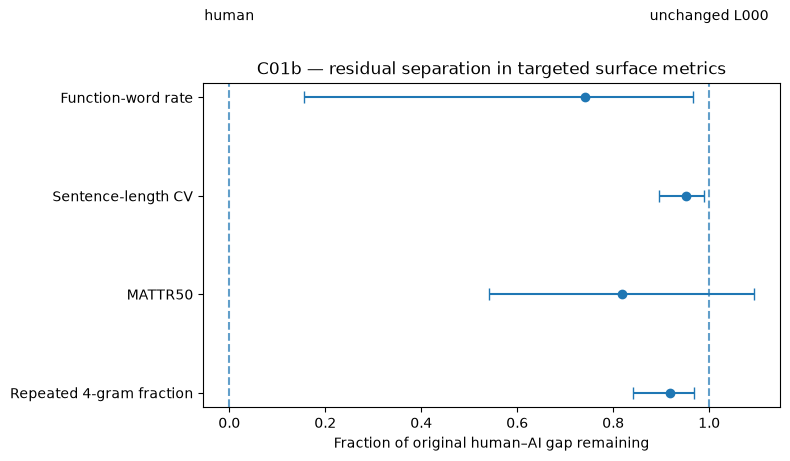

saved: ../results/causal/C01b_surface_humanization_intervention/target_metric_residual_gap_ci.png


In [25]:
# ============================================================
# C01b — paired human-gap visualization
#
# For each target metric:
#
#   gap(condition) = mean[M(condition) - M(human)]
#
# Human is therefore exactly 0.
#
# Paired bootstrap preserves the matched-source design.
# ============================================================
import matplotlib.pyplot as plt
TARGET_DISPLAY = {
    "repeat4_fraction":
        "Repeated 4-gram fraction",

    "mattr50":
        "MATTR50",

    "sentence_cv":
        "Sentence-length CV",

    "function_word_rate":
        "Function-word rate",
}


def paired_gap_bootstrap(
    metric,
    condition,
    n_boot=10_000,
    seed=SEED,
):

    z = (
        surface3[
            surface3["condition"].isin(
                ["human", condition]
            )
        ]
        .pivot(
            index="source_id",
            columns="condition",
            values=metric,
        )
        .dropna()
    )

    d = (
        z[condition]
        - z["human"]
    ).to_numpy(float)

    rr = np.random.default_rng(
        seed
    )

    bs = np.empty(
        n_boot
    )

    for b in range(
        n_boot
    ):

        ix = rr.integers(
            0,
            len(d),
            len(d),
        )

        bs[b] = (
            d[ix]
            .mean()
        )

    return {
        "metric":
            metric,

        "condition":
            condition,

        "n":
            len(d),

        "gap":
            d.mean(),

        "ci_low":
            np.quantile(
                bs,
                0.025,
            ),

        "ci_high":
            np.quantile(
                bs,
                0.975,
            ),
    }


# ------------------------------------------------------------
# Compute raw paired gaps
# ------------------------------------------------------------

rows = []

for i, metric in enumerate(
    TARGET_METRICS
):

    for j, condition in enumerate(
        [
            "L000",
            "surface_humanized",
        ]
    ):

        rows.append(
            paired_gap_bootstrap(
                metric,
                condition,
                seed=
                    SEED
                    + 20000
                    + 10 * i
                    + j,
            )
        )


gap_ci = pd.DataFrame(
    rows
)


display(
    gap_ci
)


# ------------------------------------------------------------
# Normalize by the ORIGINAL human–AI gap.
#
# This makes all four metrics comparable on one graph:
#
#     0 = human
#     1 = original L000 gap
#     transformed value = fraction of gap remaining
#
# We bootstrap the ratio jointly so denominator uncertainty
# is included.
# ------------------------------------------------------------

normalized_rows = []


for i, metric in enumerate(
    TARGET_METRICS
):

    z = (
        surface3[
            surface3["condition"].isin(
                [
                    "human",
                    "L000",
                    "surface_humanized",
                ]
            )
        ]
        .pivot(
            index="source_id",
            columns="condition",
            values=metric,
        )
        .dropna()
    )


    h = z["human"].to_numpy(
        float
    )

    b = z["L000"].to_numpy(
        float
    )

    s = z[
        "surface_humanized"
    ].to_numpy(
        float
    )


    baseline_gap = np.mean(
        b - h
    )

    surface_gap = np.mean(
        s - h
    )


    residual_fraction = (
        surface_gap
        / baseline_gap
    )


    rr = np.random.default_rng(
        SEED
        + 30000
        + i
    )


    boot = np.full(
        N_BOOT,
        np.nan,
    )


    for k in range(
        N_BOOT
    ):

        ix = rr.integers(
            0,
            len(z),
            len(z),
        )


        bg = np.mean(
            b[ix]
            - h[ix]
        )

        sg = np.mean(
            s[ix]
            - h[ix]
        )


        if abs(bg) > 1e-12:

            boot[k] = (
                sg
                / bg
            )


    valid = np.isfinite(
        boot
    )


    normalized_rows.append({
        "metric":
            metric,

        "label":
            TARGET_DISPLAY[
                metric
            ],

        "n":
            len(z),

        "baseline_gap":
            baseline_gap,

        "surface_gap":
            surface_gap,

        "fraction_gap_remaining":
            residual_fraction,

        "gap_closure":
            1
            - residual_fraction,

        "ci_low":
            np.quantile(
                boot[valid],
                0.025,
            ),

        "ci_high":
            np.quantile(
                boot[valid],
                0.975,
            ),
    })


gap_remaining = pd.DataFrame(
    normalized_rows
)


print(
    "=== FRACTION OF ORIGINAL HUMAN–AI GAP REMAINING ==="
)

display(
    gap_remaining
)


# ------------------------------------------------------------
# Forest plot
#
# 0 = human matched
# 1 = unchanged from original AI
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 4.8)
)


y = np.arange(
    len(
        gap_remaining
    )
)


x = gap_remaining[
    "fraction_gap_remaining"
].to_numpy()


xerr = np.vstack([
    x
    - gap_remaining[
        "ci_low"
    ].to_numpy(),

    gap_remaining[
        "ci_high"
    ].to_numpy()
    - x,
])


ax.errorbar(
    x,
    y,
    xerr=xerr,
    fmt="o",
    capsize=4,
)


ax.axvline(
    0,
    linestyle="--",
    alpha=0.7,
)

ax.axvline(
    1,
    linestyle="--",
    alpha=0.7,
)


ax.set_yticks(
    y
)

ax.set_yticklabels(
    gap_remaining[
        "label"
    ]
)


ax.set_xlabel(
    "Fraction of original human–AI gap remaining"
)

ax.set_title(
    "C01b — residual separation in targeted surface metrics"
)


ax.text(
    0,
    len(y) - 0.25,
    "human",
    ha="center",
    va="bottom",
)

ax.text(
    1,
    len(y) - 0.25,
    "unchanged L000",
    ha="center",
    va="bottom",
)


fig.tight_layout()


p = (
    OUT
    / "target_metric_residual_gap_ci.png"
)

fig.savefig(
    p,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    "saved:",
    p,
)


## Interpretation gate

Proceed to the factorial detector experiment only if:

- the four target metrics show substantial human-gap closure;
- `distinct4` and `adjacent_sentence_change` move humanward without direct optimization;
- accepted rewrites pass the frozen preservation gates and manual inspection;
- \(U/L\) move substantially less than under C00b;
- the transparent 4-feature surface detector weakens materially.

The later detector experiment should compare

\[
X,\qquad S(X),\qquad I_U(X),\qquad S(I_U(X)).
\]
